# 02 Results

Loads `results/` and the processed cell table (no raw data) and draws the figures saved to `results/figures/`. Every number is from the held-out test set unless a cell says CV. The random and spatial splits have different test cells, so compare a model to itself across splits, and models to each other within a split.

## Summary

All scores use the 30-day target from all five trip files (44.4M clean trips).

- **Baseline LR.** The `baseline_lr` row is least squares on raw counts of 3 POI types, trained on non-zero cells and untuned: the simplest reasonable model and the one this project started from. On unseen blocks it reaches R² 0.63, Spearman 0.85 and top-10% hit rate 0.71, but predicts negative counts for 307 of 649 cells.
- **Only boosted trees clearly beat it on unseen blocks.** XGBoost: R² 0.71, Spearman 0.92, top-10% hit rate 0.75, MAE 17% lower and Poisson deviance 45% lower. HistGradientBoosting (`hgb`) and the hurdle model land within 0.01 R² of it, so the gain comes from boosting, not one library.
- **The hurdle model** (P(any trips) x trips if any, same trees as `hgb`) predicts zero cells better (median 3 trips vs 11) but changes the overall scores by about 1%.
- **More features and fancier models are not enough on their own.** The Poisson GLM (0.51) and the GCN (0.54) have lower spatial R² than Baseline LR. Ridge on log1p is unstable after back-transforming (R² 0.34 spatial, -2.2 random), though its Spearman is 0.92. Duan's smearing correction was tried and made it worse.
- **A random split flatters every model with positive R²:** R² drops by 0.10 (XGBoost, Baseline LR) to 0.26 (Poisson GLM) on unseen blocks, and top-10% hit rate by 0.06 to 0.27.
- **The features-free spatial kNN shows the leak most clearly:** it ranks cells almost as well as the best model on the random split (Spearman 0.925 vs 0.926) and worst on unseen blocks (0.84).
- **More data barely moves the scores.** Against the one-file (8-day) runs, spatial R² rises by 0.004 to 0.018 for every model except ridge, Spearman by about 0.02 and top-10% hit rate by up to 0.05. The demand pattern is already stable after one week.
- **Errors sit at the two extremes.** The busiest 10% of test cells hold 63% of test trips and about half of XGBoost's absolute error; it predicts 0.68 of their demand (the GCN 0.48). At the other end, two dense Longhua blocks (about 340 POIs per cell) get about 2,300 trips in 30 days, steadily every week, while the tree models predict 580k to 600k.
- **Masking to cells served every week does not help.** It lowers XGBoost's spatial R² from 0.71 to 0.66: cells that miss a week hold about 3% of each feature model's absolute error (5% for kNN), and the Longhua gap cells still get a trip or two most weeks.
- **Easy zeros do not drive the headline.** Dropping trivial cells moves R² by at most 0.03.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from biketrips import config, evaluate, plots

cfg = config.load_config()
res = cfg["data"]["results_dir"]
fig_dir = res / "figures"
order = ["baseline_lr", "linear", "knn", "poisson", "xgb", "hgb", "hurdle", "gcn"]
preds = pd.read_csv(res / "predictions.csv")
cells = pd.read_parquet(cfg["data"]["processed_dir"] / "cells.parquet")
pd.set_option("display.precision", 3)

## Test scores, random vs spatial split

In [2]:
main = ["mae", "rmse", "poisson_deviance", "spearman", "top10_hit", "r2", "n_clipped"]
table = evaluate.test_table(res / "metrics.csv", main).reindex(order, level="model")
table

metric                        mae       rmse  poisson_deviance  spearman  \
model       split_type                                                     
baseline_lr random       8116.787  19449.126         12606.341     0.800   
            spatial     11045.637  26099.009         17734.911     0.854   
linear      random      13526.166  66485.536         20640.665     0.916   
            spatial     12983.401  34622.584         20751.673     0.915   
knn         random       8605.910  23401.475          9307.396     0.925   
            spatial     15394.267  33894.493         22617.887     0.841   
poisson     random       6804.042  17874.749          6619.328     0.884   
            spatial     11767.160  29828.427         12127.006     0.898   
xgb         random       6228.926  16041.742          5515.842     0.918   
            spatial      9167.970  22934.173          9719.720     0.920   
hgb         random       6309.004  16006.942          5593.878     0.917   
            spatial      9451.824  23278.844          9929.575     0.918   
hurdle      random       6394.004  16704.203          5903.968     0.926   
            spatial      9342.297  23285.777          9893.334     0.922   
gcn         random       7169.514  19183.057          7248.633     0.911   
            spatial     11779.931  28948.055         15486.503     0.910   

metric                  top10_hit     r2  n_clipped  
model       split_type                               
baseline_lr random          0.788  0.727      352.0  
            spatial         0.708  0.625      307.0  
linear      random          0.818 -2.193       92.0  
            spatial         0.677  0.340       75.0  
knn         random          0.742  0.604        0.0  
            spatial         0.477  0.367        0.0  
poisson     random          0.818  0.769        0.0  
            spatial         0.723  0.510        0.0  
xgb         random          0.818  0.814        0.0  
            spatial         0.754  0.710        0.0  
hgb         random          0.833  0.815        0.0  
            spatial         0.723  0.702        0.0  
hurdle      random          0.818  0.798        0.0  
            spatial         0.723  0.701        0.0  
gcn         random          0.803  0.734        0.0  
            spatial         0.677  0.539        0.0

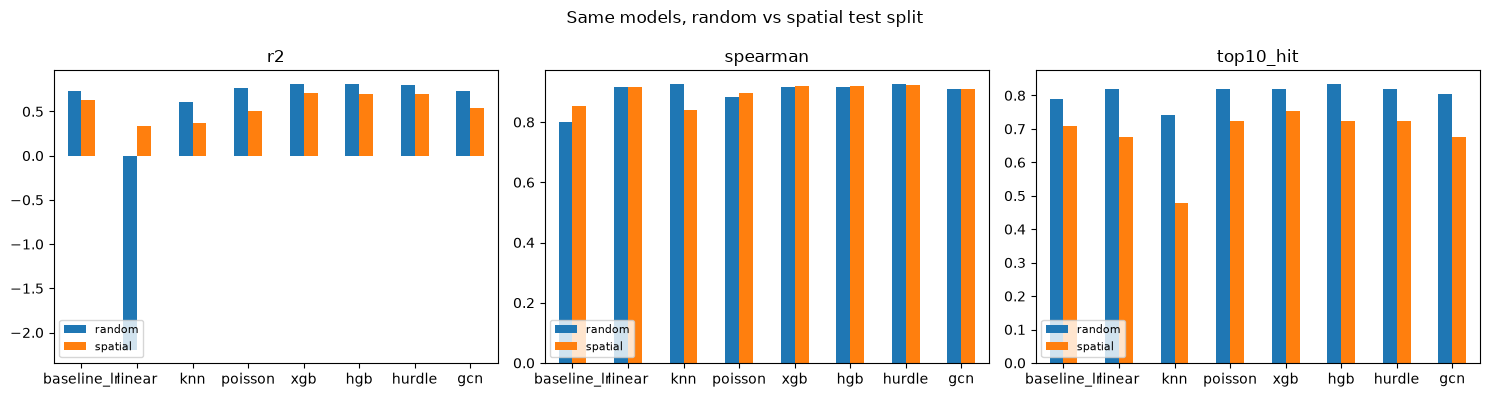

In [3]:
axes = plots.split_comparison(table, ["r2", "spearman", "top10_hit"])
plt.suptitle("Same models, random vs spatial test split")
plt.tight_layout()
plt.savefig(fig_dir / "random_vs_spatial.png", dpi=120)

## The leak, in one column

Drop from random to spatial split for each model. Positive means the random split scored higher. The kNN baseline uses only location, so its drop is the size of the spatial leak.

In [4]:
(table.xs("random", level="split_type") - table.xs("spatial", level="split_type"))[["r2", "spearman", "top10_hit"]].reindex(order)

metric,r2,spearman,top10_hit
model,,,
baseline_lr,0.102,-5.356e-02,0.080
linear,-2.533,4.263e-04,0.141
knn,0.237,8.395e-02,0.266
poisson,0.259,-1.398e-02,0.095
xgb,0.104,-1.973e-03,0.064
hgb,0.113,-1.750e-03,0.110
hurdle,0.097,3.382e-03,0.095
gcn,0.196,1.074e-03,0.126


## One trip file vs all five

The same experiments on file 21 alone (8 days, 10M trips) are archived in `results/metrics_file21.csv`. The targets differ in scale, so only scale-free metrics are compared.

In [5]:
free = ["r2", "spearman", "top10_hit"]
pd.concat({"one file": evaluate.test_table(res / "metrics_file21.csv", free),
           "five files": evaluate.test_table(res / "metrics.csv", free)}, axis=1).reindex(order, level="model")

one file                    five files           \
metric                       r2 spearman top10_hit         r2 spearman   
model       split_type                                                   
baseline_lr random        0.720    0.798     0.773      0.727    0.800   
            spatial       0.620    0.848     0.708      0.625    0.854   
linear      random       -0.471    0.892     0.803     -2.193    0.916   
            spatial      -0.104    0.882     0.615      0.340    0.915   
knn         random        0.601    0.914     0.758      0.604    0.925   
            spatial       0.355    0.777     0.492      0.367    0.841   
poisson     random        0.767    0.871     0.818      0.769    0.884   
            spatial       0.492    0.879     0.692      0.510    0.898   
xgb         random        0.803    0.900     0.848      0.814    0.918   
            spatial       0.702    0.896     0.723      0.710    0.920   
hgb         random        0.797    0.902     0.818      0.815    0.917   
            spatial       0.689    0.895     0.677      0.702    0.918   
hurdle      random        0.794    0.910     0.818      0.798    0.926   
            spatial       0.693    0.900     0.692      0.701    0.922   
gcn         random        0.730    0.897     0.788      0.734    0.911   
            spatial       0.525    0.886     0.646      0.539    0.910   

                                  
metric                 top10_hit  
model       split_type            
baseline_lr random         0.788  
            spatial        0.708  
linear      random         0.818  
            spatial        0.677  
knn         random         0.742  
            spatial        0.477  
poisson     random         0.818  
            spatial        0.723  
xgb         random         0.818  
            spatial        0.754  
hgb         random         0.833  
            spatial        0.723  
hurdle      random         0.818  
            spatial        0.723  
gcn         random         0.803  
            spatial        0.677

## Supply: scores on cells served every week

`_served` keeps only test cells with trips in all 4 weeks. The mask is built from the target, so this is an oracle: the most that knowing the operator's service area could add, not a score a deployed model would get.

In [6]:
served = ["r2", "r2_served", "spearman", "spearman_served", "top10_hit", "top10_hit_served"]
evaluate.test_table(res / "metrics.csv", served).reindex(order, level="model")

metric                     r2  r2_served  spearman  spearman_served  \
model       split_type                                                
baseline_lr random      0.727      0.683     0.800            0.805   
            spatial     0.625      0.553     0.854            0.782   
linear      random     -2.193     -2.739     0.916            0.841   
            spatial     0.340      0.209     0.915            0.825   
knn         random      0.604      0.538     0.925            0.851   
            spatial     0.367      0.255     0.841            0.740   
poisson     random      0.769      0.731     0.884            0.868   
            spatial     0.510      0.415     0.898            0.836   
xgb         random      0.814      0.783     0.918            0.881   
            spatial     0.710      0.655     0.920            0.855   
hgb         random      0.815      0.784     0.917            0.883   
            spatial     0.702      0.645     0.918            0.852   
hurdle      random      0.798      0.765     0.926            0.883   
            spatial     0.701      0.644     0.922            0.853   
gcn         random      0.734      0.689     0.911            0.851   
            spatial     0.539      0.448     0.910            0.828   

metric                  top10_hit  top10_hit_served  
model       split_type                               
baseline_lr random          0.788             0.800  
            spatial         0.708             0.632  
linear      random          0.818             0.743  
            spatial         0.677             0.553  
knn         random          0.742             0.571  
            spatial         0.477             0.368  
poisson     random          0.818             0.771  
            spatial         0.723             0.632  
xgb         random          0.818             0.800  
            spatial         0.754             0.684  
hgb         random          0.833             0.743  
            spatial         0.723             0.684  
hurdle      random          0.818             0.743  
            spatial         0.723             0.658  
gcn         random          0.803             0.800  
            spatial         0.677             0.553

## Where the error is (spatial split)

Share of each model's total absolute error by how many of the 4 weeks a test cell had any trip. `pred` and `trips` are summed over those cells.

In [7]:
err = evaluate.error_share(preds, cells)
err.xs("spatial", level="split_type")["err_share"].unstack("weeks_served").reindex(order).round(3)

weeks_served,0,1,2,3,4
model,,,,,
baseline_lr,0.003,0.003,0.008,0.020,0.967
linear,0.000,0.001,0.001,0.004,0.994
knn,0.008,0.013,0.007,0.027,0.946
poisson,0.002,0.003,0.005,0.017,0.973
xgb,0.003,0.003,0.006,0.020,0.968
hgb,0.002,0.002,0.006,0.020,0.969
hurdle,0.002,0.003,0.006,0.020,0.969
gcn,0.003,0.003,0.004,0.013,0.977


In [8]:
err.xs(("xgb", "spatial"), level=["model", "split_type"])

,cells,trips,pred,abs_err,err_share
weeks_served,,,,,
0,166,8,1.593e+04,1.592e+04,0.003
1,45,66,1.825e+04,1.819e+04,0.003
2,20,89,3.655e+04,3.646e+04,0.006
3,41,340,1.187e+05,1.184e+05,0.020
4,377,13251803,1.091e+07,5.761e+06,0.968


## With and without trivial cells

Trivial cells have zero POIs and zero or unknown population (water, mountains, border strip). They are easy zeros. Scores without them show whether easy zeros inflate the headline.

In [9]:
both = ["r2", "r2_nontrivial", "spearman", "spearman_nontrivial", "top10_hit", "top10_hit_nontrivial"]
evaluate.test_table(res / "metrics.csv", both).reindex(order, level="model")

metric                     r2  r2_nontrivial  spearman  spearman_nontrivial  \
model       split_type                                                        
baseline_lr random      0.727          0.718     0.800                0.800   
            spatial     0.625          0.606     0.854                0.839   
linear      random     -2.193         -2.296     0.916                0.909   
            spatial     0.340          0.306     0.915                0.889   
knn         random      0.604          0.592     0.925                0.927   
            spatial     0.367          0.362     0.841                0.849   
poisson     random      0.769          0.762     0.884                0.887   
            spatial     0.510          0.485     0.898                0.880   
xgb         random      0.814          0.808     0.918                0.917   
            spatial     0.710          0.695     0.920                0.898   
hgb         random      0.815          0.809     0.917                0.919   
            spatial     0.702          0.686     0.918                0.896   
hurdle      random      0.798          0.792     0.926                0.925   
            spatial     0.701          0.686     0.922                0.899   
gcn         random      0.734          0.726     0.911                0.909   
            spatial     0.539          0.515     0.910                0.883   

metric                  top10_hit  top10_hit_nontrivial  
model       split_type                                   
baseline_lr random          0.788                 0.745  
            spatial         0.708                 0.704  
linear      random          0.818                 0.691  
            spatial         0.677                 0.611  
knn         random          0.742                 0.709  
            spatial         0.477                 0.463  
poisson     random          0.818                 0.764  
            spatial         0.723                 0.648  
xgb         random          0.818                 0.800  
            spatial         0.754                 0.722  
hgb         random          0.833                 0.800  
            spatial         0.723                 0.685  
hurdle      random          0.818                 0.800  
            spatial         0.723                 0.685  
gcn         random          0.803                 0.745  
            spatial         0.677                 0.667

## Inner CV vs test (spatial)

Mean over the 5 inner folds for the chosen hyperparameters, next to the single held-out test score.

In [10]:
m = evaluate.latest(res / "metrics.csv")
m = m[(m["split_type"] == "spatial") & m["metric"].isin(["r2", "spearman", "top10_hit"])]
m.assign(set=m["fold"].where(m["fold"] == "test", "cv_mean")).pivot_table(
    index="model", columns=["metric", "set"], values="value").reindex(order)

metric           r2        spearman        top10_hit       
set         cv_mean   test  cv_mean   test   cv_mean   test
model                                                      
baseline_lr   0.671  0.625    0.785  0.854     0.698  0.708
linear       -0.479  0.340    0.893  0.915     0.714  0.677
knn           0.149  0.367    0.746  0.841     0.454  0.477
poisson       0.737  0.510    0.860  0.898     0.751  0.723
xgb           0.731  0.710    0.894  0.920     0.755  0.754
hgb           0.726  0.702    0.895  0.918     0.778  0.723
hurdle        0.736  0.701    0.901  0.922     0.769  0.723
gcn           0.650  0.539    0.882  0.910     0.736  0.677

## Top-k hit rate

If a planner can place stations in the top k% of cells, how many of the true top k% does each model find?

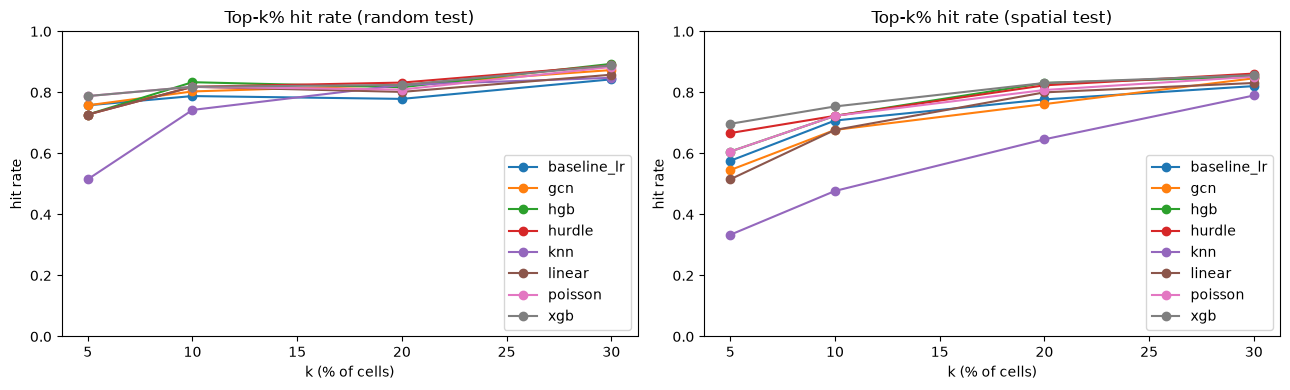

In [11]:
curve = evaluate.hit_curve(preds, [0.05, 0.1, 0.2, 0.3])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plots.hit_curve(curve, ax[0], "random")
plots.hit_curve(curve, ax[1], "spatial")
ax[0].set_ylim(0, 1); ax[1].set_ylim(0, 1)
plt.tight_layout()
plt.savefig(fig_dir / "topk_hit_rate.png", dpi=120)

## Residual maps (spatial test cells)

Held-out blocks show where each model fails. Red means over-predicted.

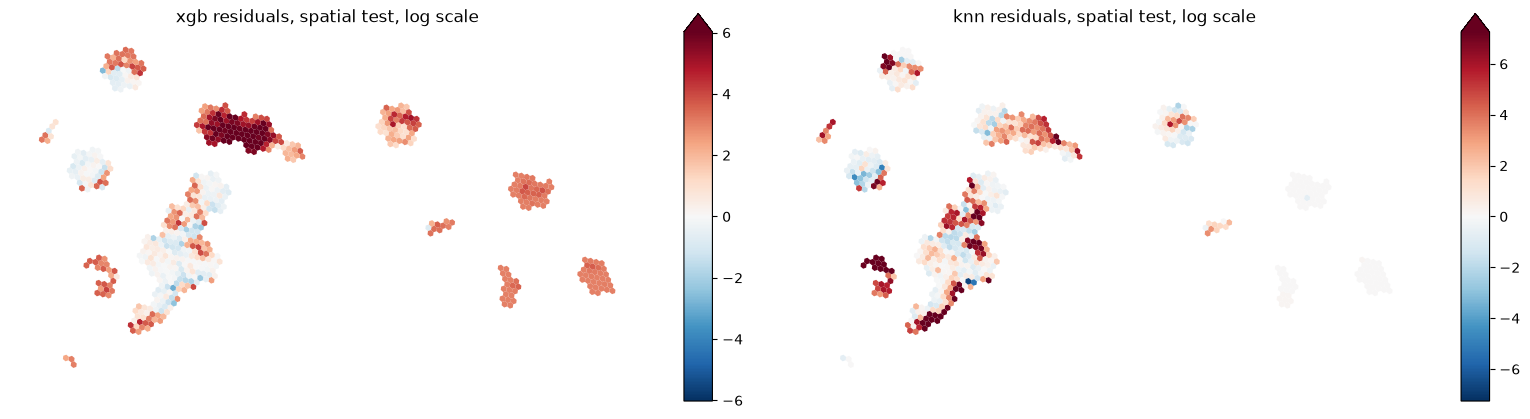

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plots.residual_map(preds, "xgb", "spatial", ax[0])
plots.residual_map(preds, "knn", "spatial", ax[1])
plt.tight_layout()
plt.savefig(fig_dir / "residual_map.png", dpi=120)

## Feature importance (XGBoost, spatial split)

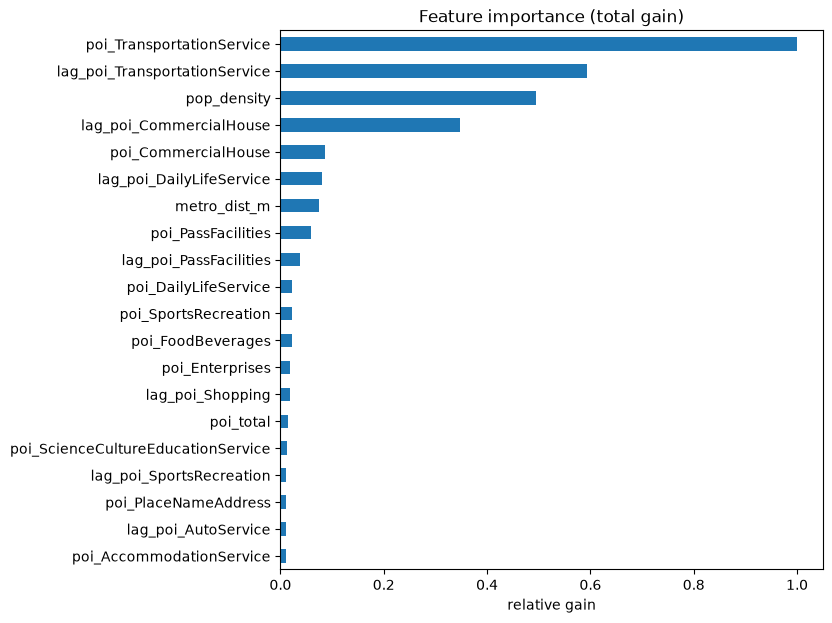

In [13]:
imp = pd.read_csv(res / "xgb_importance.csv", index_col="feature")["total_gain"]
plots.importance(imp);  # saved as figures/xgb_importance.png by run_experiments.py

## Chosen hyperparameters

In [14]:
print(yaml.safe_dump(yaml.safe_load((res / "best_params.yaml").read_text()), sort_keys=False))

linear:
  random:
    alpha: 100.0
  spatial:
    alpha: 100.0
knn:
  random:
    k: 3
  spatial:
    k: 8
poisson:
  random:
    alpha: 10.0
  spatial:
    alpha: 10.0
xgb:
  random:
    n_estimators: 488
    max_depth: 4
    learning_rate: 0.0389428920348173
    min_child_weight: 4
    subsample: 0.6017774608893249
    colsample_bytree: 0.7048192439418706
    reg_lambda: 3.776382296107197
  spatial:
    n_estimators: 230
    max_depth: 4
    learning_rate: 0.05815056998913016
    min_child_weight: 6
    subsample: 0.8468942487517535
    colsample_bytree: 0.5563607644731673
    reg_lambda: 3.588438611877875
gcn:
  random:
    dropout: 0.3
    hidden: 16
    k: 4
    lr: 0.003
    max_epochs: 2000
    patience: 100
    val_frac: 0.2
  spatial:
    dropout: 0.3
    hidden: 16
    k: 4
    lr: 0.003
    max_epochs: 2000
    patience: 100
    val_frac: 0.2
baseline_lr:
  random:
    nonzero_only: true
  spatial:
    nonzero_only: true
hgb:
  random:
    max_iter: 468
    max_depth: 7
    